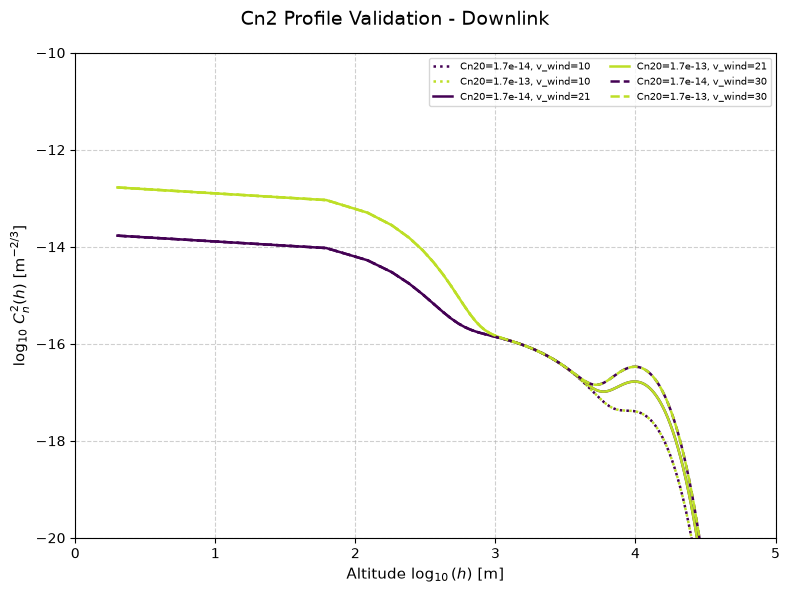

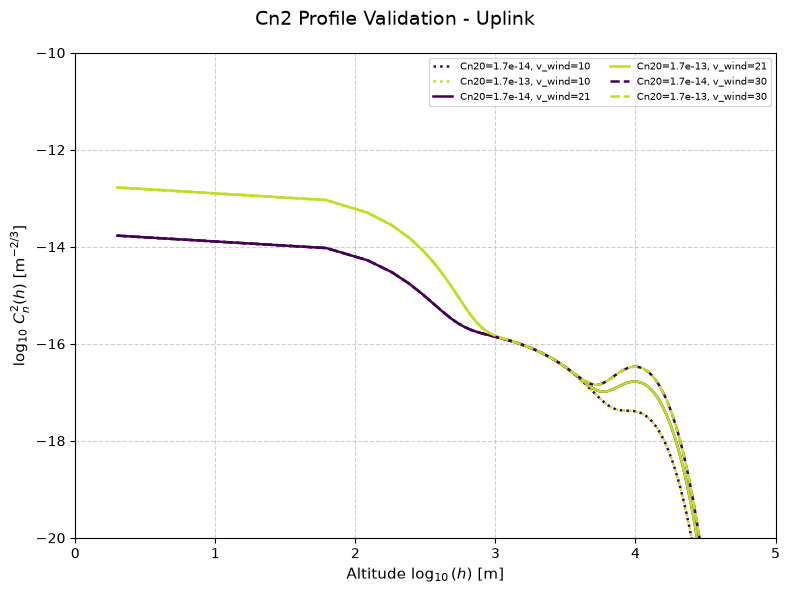

In [1]:
# We want to replicate figure 2.1 (sec. 12.2.1) of  L. C. Andrews and R. L. Phillips, "Laser Beam Propagation through Random Media".

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_cn2_validation.csv"
df = pd.read_csv(INPUT_FILE)

df = df.sort_values(["scenario", "v_wind", "Cn20", "h"])

scenarios = df["scenario"].unique()
cn20_values = sorted(df["Cn20"].unique())
vwind_values = sorted(df["v_wind"].unique())

# ------------------------------------------------------------
# Plot style: one color per Cn20 value, one line style per v_wind
# ------------------------------------------------------------

cn20_colors = plt.cm.viridis(np.linspace(0, 0.9, len(cn20_values)))
cn20_color_map = dict(zip(cn20_values, cn20_colors))

# 1st = dotted, 2nd = solid, 3rd = dashed (dash-dot as fallback)
vwind_linestyles = [":", "-", "--", "-."]
vwind_linestyle_map = {
    v: vwind_linestyles[i % len(vwind_linestyles)] for i, v in enumerate(vwind_values)
}

# ------------------------------------------------------------
# Create one figure per scenario: Cn2(h) vs altitude
# ------------------------------------------------------------

for scenario in scenarios:
    scen_df = df[df["scenario"] == scenario]
    if scen_df.empty:
        continue

    fig, ax = plt.subplots(figsize=(8, 6))
    fig.suptitle(f"Cn2 Profile Validation - {scenario}", fontsize=14)

    for (v_wind, cn20), case_df in scen_df.groupby(["v_wind", "Cn20"]):

        ax.plot(
            np.log10(case_df["h"]),
            np.log10(case_df["Cn2h"]),
            linestyle=vwind_linestyle_map[v_wind],
            linewidth=1.8,
            color=cn20_color_map[cn20],
            label=f"Cn20={cn20:.1e}, v_wind={v_wind:.0f}",
        )

    ax.set_xlabel(r"Altitude $\log_{10}(h)$ [m]", fontsize=11)
    ax.set_ylabel(r"$\log_{10}\,C_n^2(h)$ [m$^{-2/3}$]", fontsize=11)
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(fontsize=7, ncol=2)

    ax.set_xlim(0.0, 5)
    ax.set_ylim(-20, -10)

    plt.tight_layout()
    
    # plt.savefig(f"./figures/qdl_fso_cn2_{str.lower(scenario)}.pdf")
    plt.savefig(f"./figures/qdl_fso_cn2_{str.lower(scenario)}.png")

    plt.show()

    plt.close(fig)